PreProcessing for Task A

In [29]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder
import joblib

In [4]:
medical_df = pd.read_csv('data/insurance.csv')
medical_df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


(EDA)

In [5]:
# Statistical summary
print(medical_df.describe(include="all"))

                age   sex          bmi     children smoker     region  \
count   1338.000000  1338  1338.000000  1338.000000   1338       1338   
unique          NaN     2          NaN          NaN      2          4   
top             NaN  male          NaN          NaN     no  southeast   
freq            NaN   676          NaN          NaN   1064        364   
mean      39.207025   NaN    30.663397     1.094918    NaN        NaN   
std       14.049960   NaN     6.098187     1.205493    NaN        NaN   
min       18.000000   NaN    15.960000     0.000000    NaN        NaN   
25%       27.000000   NaN    26.296250     0.000000    NaN        NaN   
50%       39.000000   NaN    30.400000     1.000000    NaN        NaN   
75%       51.000000   NaN    34.693750     2.000000    NaN        NaN   
max       64.000000   NaN    53.130000     5.000000    NaN        NaN   

             charges  
count    1338.000000  
unique           NaN  
top              NaN  
freq             NaN  
mean    

In [6]:
medical_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   str    
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   str    
 5   region    1338 non-null   str    
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 73.3 KB


In [7]:
# Missing values count
print("Missing values count:")
print(medical_df.isnull().sum())

Missing values count:
age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64


In [8]:
# Duplicate rows count and removal
print("Number of duplicate rows:", medical_df.duplicated().sum())
medical_df = medical_df.drop_duplicates()
print("Number of duplicate rows:", medical_df.duplicated().sum())

Number of duplicate rows: 1
Number of duplicate rows: 0


In [9]:
# Value counts
print("Value counts for 'sex':")
print(medical_df["sex"].value_counts())

Value counts for 'sex':
sex
male      675
female    662
Name: count, dtype: int64


In [10]:
print("Value counts for 'smoker':")
print(medical_df["smoker"].value_counts())

Value counts for 'smoker':
smoker
no     1063
yes     274
Name: count, dtype: int64


In [11]:
print("Value counts for 'region':")
print(medical_df["region"].value_counts())

Value counts for 'region':
region
southeast    364
southwest    325
northwest    324
northeast    324
Name: count, dtype: int64


In [12]:
# Average charges by smoker
print("Average charges by smoker:")
print(medical_df.groupby("smoker")["charges"].mean())

Average charges by smoker:
smoker
no      8440.660307
yes    32050.231832
Name: charges, dtype: float64


In [13]:
# Average charges by sex and smoker
print("Average charges by sex and smoker:")
print(medical_df.groupby(["sex", "smoker"])["charges"].mean())

Average charges by sex and smoker:
sex     smoker
female  no         8762.297300
        yes       30678.996276
male    no         8099.700161
        yes       33042.005975
Name: charges, dtype: float64


In [14]:
# Correlation with charges
print("Correlation with charges:")
print(
    medical_df.corr(numeric_only=True)["charges"]
    .sort_values(ascending=False)
)

Correlation with charges:
charges     1.000000
age         0.298308
bmi         0.198401
children    0.067389
Name: charges, dtype: float64


Outlier Detection

In [15]:
Q1 = medical_df["charges"].quantile(0.25)
Q3 = medical_df["charges"].quantile(0.75)
IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

outliers = medical_df[
    (medical_df["charges"] < lower) |
    (medical_df["charges"] > upper)
]

print("Number of outliers:", len(outliers))
print(
    "Outliers percentage:",
    int(len(outliers) / len(medical_df) * 100),
    "%"
)

Number of outliers: 139
Outliers percentage: 10 %


Plotting 

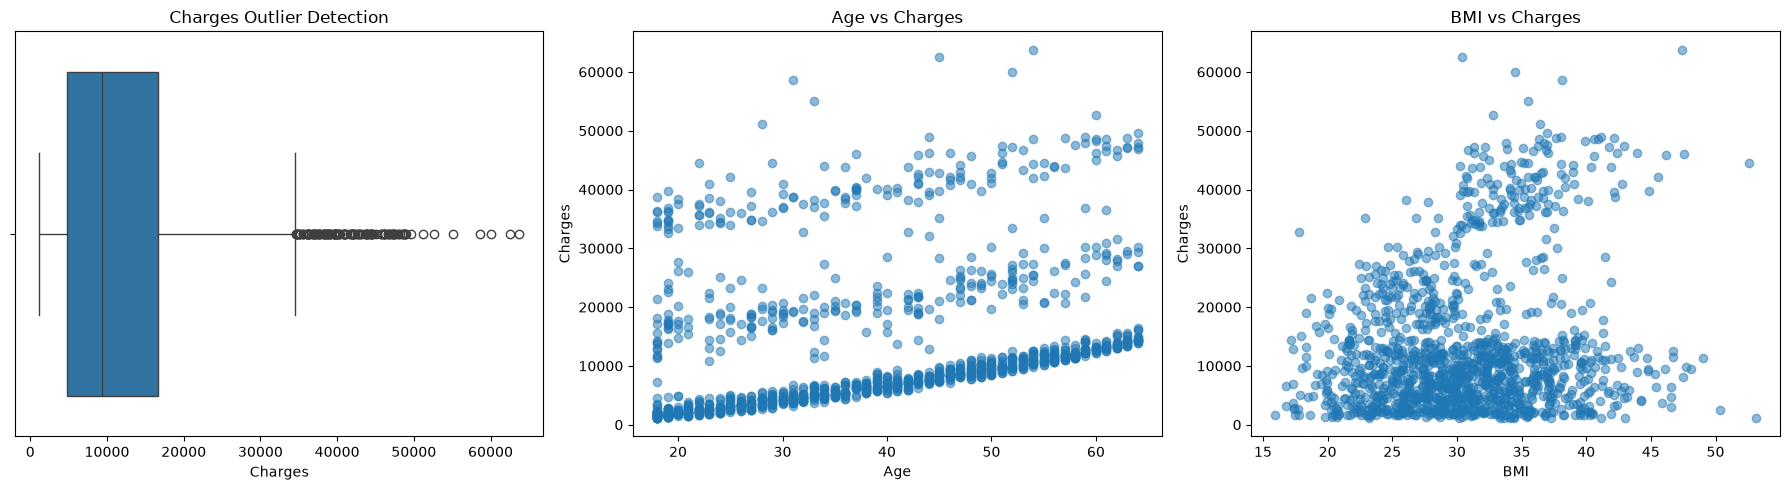

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Charges outliers
sns.boxplot(x=medical_df["charges"], ax=axes[0])
axes[0].set_title("Charges Outlier Detection")
axes[0].set_xlabel("Charges")

# 2. Relationship between Age and Charges
axes[1].scatter(
    medical_df["age"],
    medical_df["charges"],
    alpha=0.5
)
axes[1].set_title("Age vs Charges")
axes[1].set_xlabel("Age")
axes[1].set_ylabel("Charges")

# 3. Relationship between BMI and Charges
axes[2].scatter(
    medical_df["bmi"],
    medical_df["charges"],
    alpha=0.5
)
axes[2].set_title("BMI vs Charges")
axes[2].set_xlabel("BMI")
axes[2].set_ylabel("Charges")

plt.tight_layout()
plt.show()

Data Cleaning

In [17]:
# Remove rows with missing target values
medical_df = medical_df.dropna(subset=["charges"])

# Separate smokers and non-smokers
non_smoker = medical_df[medical_df["smoker"] == "no"]
smoker = medical_df[medical_df["smoker"] == "yes"]

In [18]:
medical_df_without_charges = medical_df.drop(columns=["charges"])
inputs = medical_df_without_charges
target = medical_df["charges"]

num_cols = inputs.select_dtypes(include=["number"]).columns.tolist()
cat_cols = inputs.select_dtypes(include=["string", "category"]).columns.tolist()

# Optional: inspect selected columns
print("Numeric columns:", num_cols)
print("Categorical columns:", cat_cols)

Numeric columns: ['age', 'bmi', 'children']
Categorical columns: ['sex', 'smoker', 'region']


Split Dataset into Train, Validation, and Test Sets (70/15/15)

In [19]:
# Split before preprocessing to avoid data leakage
X_train, X_temp, y_train, y_temp = train_test_split(
    inputs,
    target,
    test_size=0.30,
    random_state=42
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42
)

 Preprocessing Pipelines

In [20]:
# Numerical pipeline
num_pipes = make_pipeline(
    SimpleImputer(strategy="mean"),
    MinMaxScaler()
)

# Categorical pipeline
cat_pipes = make_pipeline(
    SimpleImputer(strategy="most_frequent"),
    OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False,
        drop="if_binary"
    )
)

# Apply the appropriate pipeline to each column type
preprocessing = ColumnTransformer([
    ("num", num_pipes, num_cols),
    ("cat", cat_pipes, cat_cols)
])

In [21]:
train_pre = preprocessing.fit_transform(X_train)
val_pre = preprocessing.transform(X_val)
test_pre = preprocessing.transform(X_test)

In [23]:
enc_cols = list(
    preprocessing.named_transformers_["cat"]
    .named_steps["onehotencoder"]
    .get_feature_names_out(cat_cols)
)

In [27]:
enc_cols


['sex_male',
 'smoker_yes',
 'region_northeast',
 'region_northwest',
 'region_southeast',
 'region_southwest']

In [24]:
X_train_pre = pd.DataFrame(
    train_pre,
    columns=num_cols + enc_cols,
    index=X_train.index
)

X_val_pre = pd.DataFrame(
    val_pre,
    columns=num_cols + enc_cols,
    index=X_val.index
)

X_test_pre = pd.DataFrame(
    test_pre,
    columns=num_cols + enc_cols,
    index=X_test.index
)

print("Training set shape:", X_train_pre.shape)
print("Validation set shape:", X_val_pre.shape)
print("Test set shape:", X_test_pre.shape)

Training set shape: (935, 9)
Validation set shape: (201, 9)
Test set shape: (201, 9)


In [26]:
X_train_pre.head()

,age,bmi,children,sex_male,smoker_yes,region_northeast,region_northwest,region_southeast,region_southwest
138,0.782609,0.428840,0.6,0.0,0.0,0.0,0.0,1.0,0.0
381,0.804348,0.396153,0.0,1.0,1.0,1.0,0.0,0.0,0.0
292,0.152174,0.795803,0.4,1.0,1.0,0.0,0.0,1.0,0.0
1090,0.630435,0.544256,0.0,1.0,1.0,0.0,0.0,1.0,0.0
893,0.630435,0.618241,0.4,1.0,1.0,0.0,0.0,1.0,0.0


In [28]:
X_test_pre.to_csv('data/X_test_pre.csv', index=False)
X_train_pre.to_csv('data/X_train_pre.csv', index=False)
X_val_pre.to_csv('data/X_val_pre.csv', index=False)
y_test.to_csv('data/y_test.csv', index=False)
y_train.to_csv('data/y_train.csv', index=False)
y_val.to_csv('data/y_val.csv', index=False)

In [34]:
joblib.dump(preprocessing, '../models/numerical_preprocessing.pkl')

['../models/numerical_preprocessing.pkl']